# Home Credit Default Risk
## 피처 엔지니어링 + 리스크 세그멘테이션 분석

**분석 흐름**
```
1. 환경 설정 & 데이터 로드
2. 기초 EDA (application_train)
3. 피처 엔지니어링 (8개 테이블 집계)
4. 결측치 처리 & 스케일링
5. K-Means 클러스터링
6. DBSCAN (이상치 탐지)
7. PCA 시각화
8. 클러스터별 인사이트
```

---
## 1. 환경 설정 & 데이터 로드

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from pathlib import Path

# 한글 폰트
for fname in ['AppleGothic', 'Apple SD Gothic Neo', 'NanumGothic', 'Malgun Gothic']:
    try:
        fp = fm.findfont(fm.FontProperties(family=fname), fallback_to_default=False)
        if fp:
            plt.rcParams['font.family'] = fname
            break
    except:
        pass
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

# 색상 팔레트
C1 = '#1e3a6f'; C2 = '#2fa896'; C3 = '#e06070'
C4 = '#f5a623'; C5 = '#8855cc'; C6 = '#3a8fd4'
PALETTE = [C1, C2, C3, C4, C5, C6]

DATA = Path('home-credit-default-risk')
print('데이터 경로:', DATA)
print('파일 목록:')
for f in sorted(DATA.glob('*.csv')):
    size_mb = f.stat().st_size / 1024 / 1024
    print(f'  {f.name:<45} {size_mb:>8.1f} MB')

데이터 경로: home-credit-default-risk
파일 목록:
  HomeCredit_columns_description.csv                 0.0 MB
  POS_CASH_balance.csv                             374.5 MB
  application_test.csv                              25.3 MB
  application_train.csv                            158.4 MB
  bureau.csv                                       162.1 MB
  bureau_balance.csv                               358.2 MB
  credit_card_balance.csv                          404.9 MB
  installments_payments.csv                        689.6 MB
  previous_application.csv                         386.2 MB
  sample_submission.csv                              0.5 MB


In [2]:
# 메인 테이블 로드
print('application_train 로딩 중...')
app = pd.read_csv(DATA / 'application_train.csv')
print(f'  shape: {app.shape}')
print(f'  TARGET 분포: {app["TARGET"].value_counts().to_dict()}')
print(f'  연체율: {app["TARGET"].mean():.4f} ({app["TARGET"].mean()*100:.2f}%)')

application_train 로딩 중...
  shape: (307511, 122)
  TARGET 분포: {0: 282686, 1: 24825}
  연체율: 0.0807 (8.07%)


---
## 2. 기초 EDA

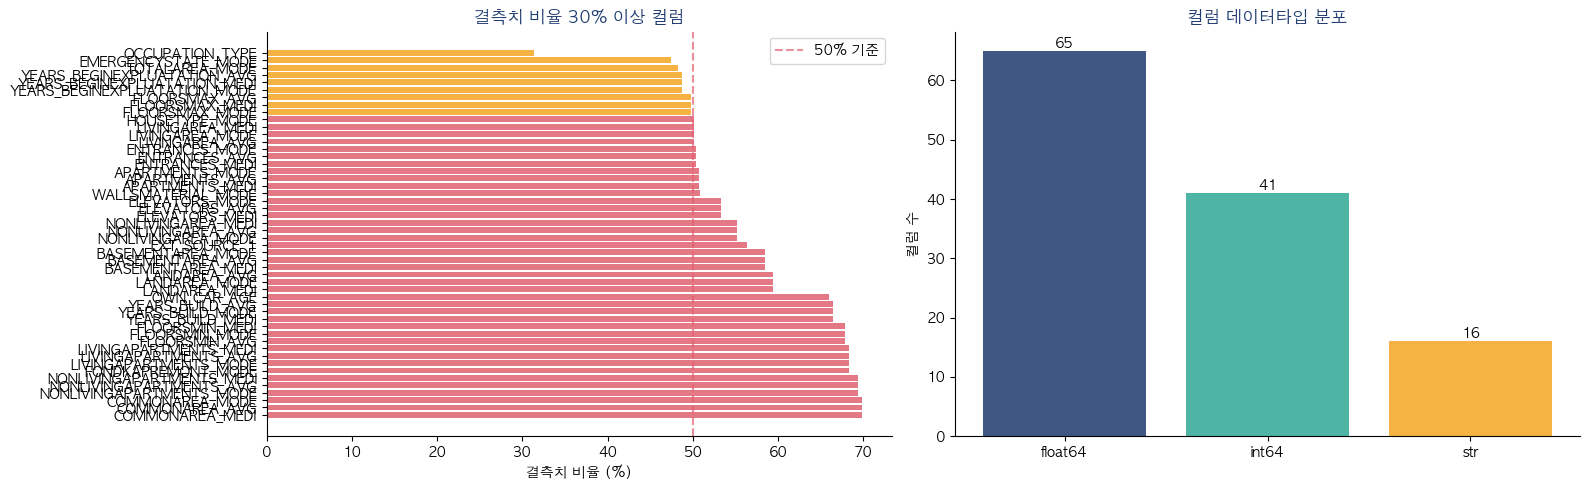

총 50개 컬럼이 결측치 30% 이상


In [3]:
# 결측치 현황
miss = app.isnull().mean().sort_values(ascending=False)
miss_top = miss[miss > 0.3]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 결측치 바 차트
colors_miss = [C3 if v > 0.5 else C4 if v > 0.3 else C6 for v in miss_top.values]
axes[0].barh(miss_top.index, miss_top.values * 100, color=colors_miss, alpha=0.85)
axes[0].set_xlabel('결측치 비율 (%)')
axes[0].set_title('결측치 비율 30% 이상 컬럼', fontweight='bold', color=C1)
axes[0].axvline(50, color=C3, lw=1.5, ls='--', alpha=0.7, label='50% 기준')
axes[0].legend()

# 데이터타입 분포
dtype_counts = app.dtypes.value_counts()
axes[1].bar([str(d) for d in dtype_counts.index], dtype_counts.values,
            color=[C1, C2, C4], alpha=0.85)
axes[1].set_title('컬럼 데이터타입 분포', fontweight='bold', color=C1)
axes[1].set_ylabel('컬럼 수')
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(int(bar.get_height())), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()
print(f'총 {len(miss_top)}개 컬럼이 결측치 30% 이상')

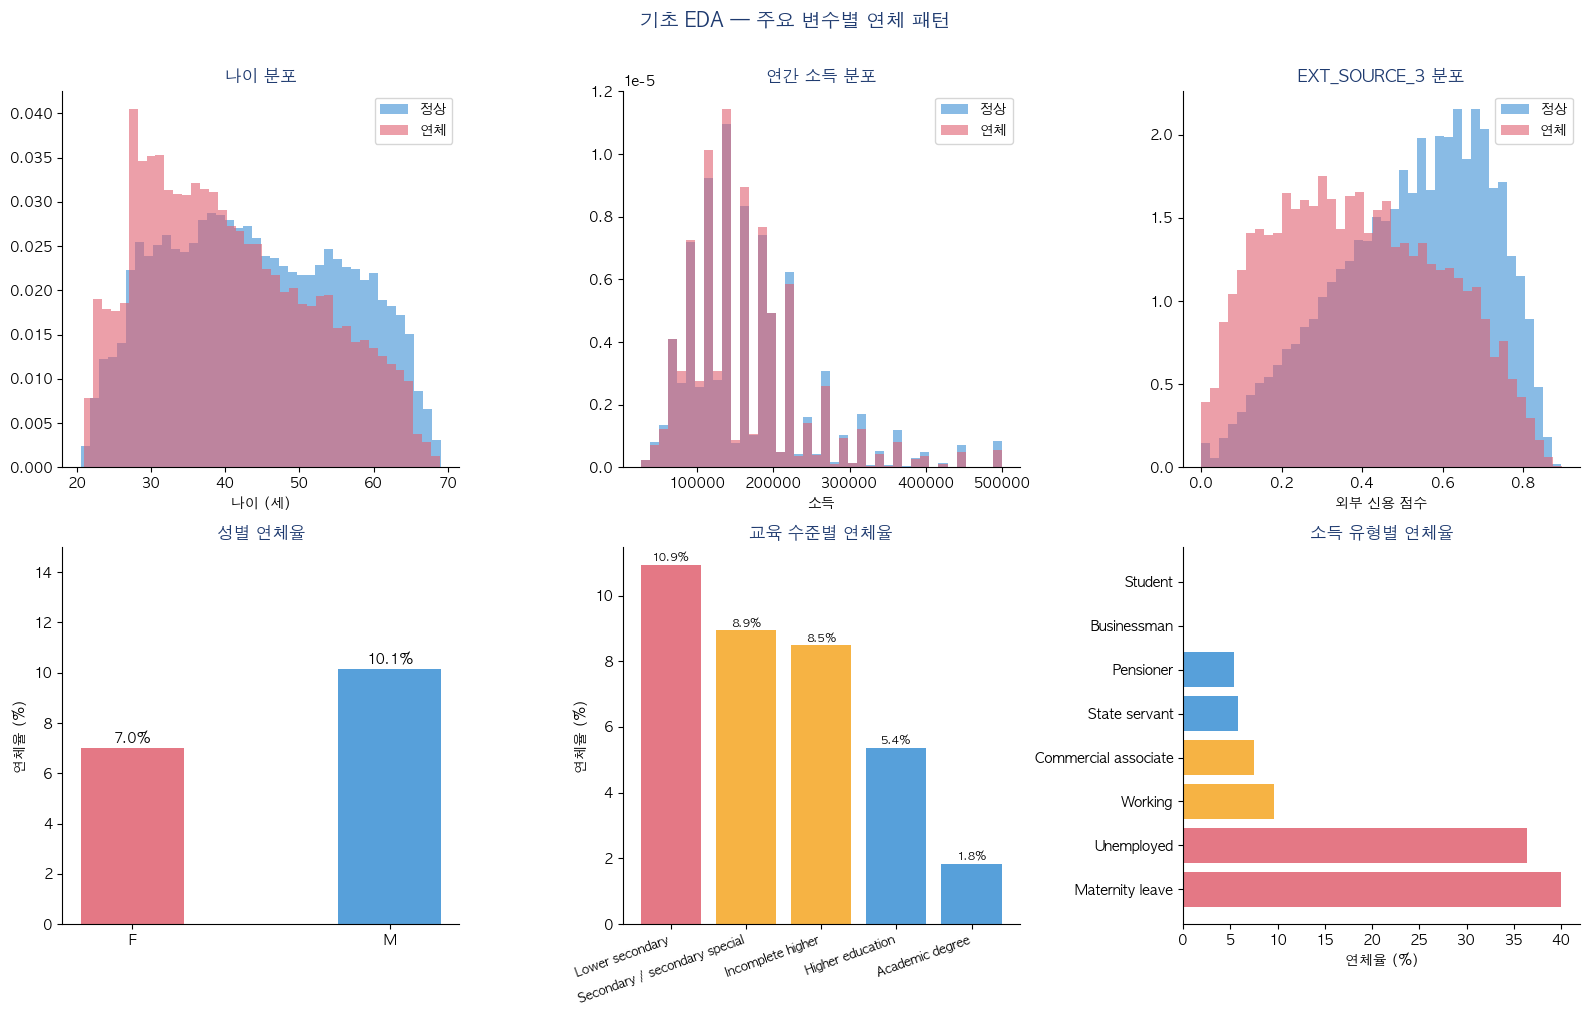

In [4]:
# TARGET별 주요 수치 비교
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. 나이 분포
app['AGE'] = -app['DAYS_BIRTH'] / 365
for tgt, color, lbl in [(0, C6, '정상'), (1, C3, '연체')]:
    axes[0,0].hist(app[app['TARGET']==tgt]['AGE'], bins=40,
                   color=color, alpha=0.6, label=lbl, density=True)
axes[0,0].set_title('나이 분포', fontweight='bold', color=C1)
axes[0,0].set_xlabel('나이 (세)')
axes[0,0].legend()

# 2. 소득 분포
for tgt, color, lbl in [(0, C6, '정상'), (1, C3, '연체')]:
    axes[0,1].hist(app[app['TARGET']==tgt]['AMT_INCOME_TOTAL'].clip(0, 500000),
                   bins=40, color=color, alpha=0.6, label=lbl, density=True)
axes[0,1].set_title('연간 소득 분포', fontweight='bold', color=C1)
axes[0,1].set_xlabel('소득')
axes[0,1].legend()

# 3. EXT_SOURCE_3 분포
for tgt, color, lbl in [(0, C6, '정상'), (1, C3, '연체')]:
    d = app[(app['TARGET']==tgt) & app['EXT_SOURCE_3'].notna()]['EXT_SOURCE_3']
    axes[0,2].hist(d, bins=40, color=color, alpha=0.6, label=lbl, density=True)
axes[0,2].set_title('EXT_SOURCE_3 분포', fontweight='bold', color=C1)
axes[0,2].set_xlabel('외부 신용 점수')
axes[0,2].legend()

# 4. 성별 연체율
gender_dr = app[app['CODE_GENDER'].isin(['M','F'])].groupby('CODE_GENDER')['TARGET'].mean() * 100
bars = axes[1,0].bar(gender_dr.index, gender_dr.values,
                     color=[C3, C6], alpha=0.85, width=0.4)
for b in bars:
    axes[1,0].text(b.get_x()+b.get_width()/2, b.get_height()+0.2,
                   f'{b.get_height():.1f}%', ha='center', fontweight='bold')
axes[1,0].set_title('성별 연체율', fontweight='bold', color=C1)
axes[1,0].set_ylabel('연체율 (%)')
axes[1,0].set_ylim(0, 15)

# 5. 교육 수준별 연체율
edu_dr = app.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().sort_values(ascending=False) * 100
bars2 = axes[1,1].bar(range(len(edu_dr)), edu_dr.values,
                      color=[C3 if v>10 else C4 if v>7 else C6 for v in edu_dr.values],
                      alpha=0.85)
axes[1,1].set_xticks(range(len(edu_dr)))
axes[1,1].set_xticklabels(edu_dr.index, rotation=20, ha='right', fontsize=9)
axes[1,1].set_title('교육 수준별 연체율', fontweight='bold', color=C1)
axes[1,1].set_ylabel('연체율 (%)')
for b in bars2:
    axes[1,1].text(b.get_x()+b.get_width()/2, b.get_height()+0.1,
                   f'{b.get_height():.1f}%', ha='center', fontsize=8)

# 6. 소득 유형별 연체율
inc_dr = app.groupby('NAME_INCOME_TYPE')['TARGET'].mean().sort_values(ascending=False) * 100
bars3 = axes[1,2].barh(inc_dr.index, inc_dr.values,
                       color=[C3 if v>10 else C4 if v>7 else C6 for v in inc_dr.values],
                       alpha=0.85)
axes[1,2].set_title('소득 유형별 연체율', fontweight='bold', color=C1)
axes[1,2].set_xlabel('연체율 (%)')

plt.suptitle('기초 EDA — 주요 변수별 연체 패턴', fontsize=14,
             fontweight='bold', color=C1, y=1.01)
plt.tight_layout()
plt.show()

---
## 3. 피처 엔지니어링

8개 테이블에서 `SK_ID_CURR` 기준으로 집계 피처를 만들어 하나의 피처셋으로 합칩니다.

### 3-1. application_train 기본 피처

In [5]:
feat = app[['SK_ID_CURR', 'TARGET']].copy()

# 나이 / 재직기간
feat['AGE']            = -app['DAYS_BIRTH'] / 365
feat['YEARS_EMPLOYED'] = (-app['DAYS_EMPLOYED'] / 365).clip(lower=0)
feat.loc[app['DAYS_EMPLOYED'] > 0, 'YEARS_EMPLOYED'] = 0  # 미취업자 → 0
feat['UNEMPLOYED_FLAG'] = (app['DAYS_EMPLOYED'] > 0).astype(int)

# 금융 비율
feat['CREDIT_INCOME_RATIO']  = app['AMT_CREDIT']  / (app['AMT_INCOME_TOTAL'] + 1)
feat['ANNUITY_INCOME_RATIO'] = app['AMT_ANNUITY'] / (app['AMT_INCOME_TOTAL'] + 1)
feat['CREDIT_GOODS_RATIO']   = app['AMT_CREDIT']  / (app['AMT_GOODS_PRICE']  + 1)

# EXT_SOURCE
ext = app[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']]
feat['EXT_SOURCE_MEAN'] = ext.mean(axis=1)
feat['EXT_SOURCE_MIN']  = ext.min(axis=1)
feat['EXT_SOURCE_MAX']  = ext.max(axis=1)
feat['EXT_SOURCE_STD']  = ext.std(axis=1)
feat['EXT_SOURCE_PROD'] = (app['EXT_SOURCE_1'].fillna(0.5) *
                           app['EXT_SOURCE_2'].fillna(0.5) *
                           app['EXT_SOURCE_3'].fillna(0.5))

# 소득 금액
feat['AMT_INCOME']  = app['AMT_INCOME_TOTAL']
feat['AMT_CREDIT']  = app['AMT_CREDIT']
feat['AMT_ANNUITY'] = app['AMT_ANNUITY']

# 주민등록/신분증 변경 이력
feat['DAYS_ID_PUBLISH']         = -app['DAYS_ID_PUBLISH']
feat['DAYS_LAST_PHONE_CHANGE']  = -app['DAYS_LAST_PHONE_CHANGE']
feat['DAYS_REGISTRATION']       = -app['DAYS_REGISTRATION']

# 지역 등급
feat['REGION_RATING'] = app['REGION_RATING_CLIENT_W_CITY']

# 플래그
feat['OWN_CAR']    = (app['FLAG_OWN_CAR']    == 'Y').astype(int)
feat['OWN_REALTY'] = (app['FLAG_OWN_REALTY'] == 'Y').astype(int)
feat['GENDER_M']   = (app['CODE_GENDER']     == 'M').astype(int)

print(f'기본 피처 생성 완료: {feat.shape[1]-2}개')
feat.head(3)

기본 피처 생성 완료: 21개


,SK_ID_CURR,TARGET,AGE,YEARS_EMPLOYED,UNEMPLOYED_FLAG,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,EXT_SOURCE_MEAN,EXT_SOURCE_MIN,...,AMT_INCOME,AMT_CREDIT,AMT_ANNUITY,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE,DAYS_REGISTRATION,REGION_RATING,OWN_CAR,OWN_REALTY,GENDER_M
0,100002,1,25.920548,1.745205,0,2.007879,0.121977,1.158394,0.161787,0.083037,...,202500.0,406597.5,24700.5,2120,1134.0,3648.0,2,0,1,1
1,100003,0,45.931507,3.254795,0,4.790732,0.132216,1.145198,0.466757,0.311267,...,270000.0,1293502.5,35698.5,291,828.0,1186.0,1,0,0,0
2,100004,0,52.180822,0.616438,0,1.999970,0.099999,0.999993,0.642739,0.555912,...,67500.0,135000.0,6750.0,2531,815.0,4260.0,2,1,1,1


### 3-2. bureau 집계 피처

In [6]:
print('bureau 로딩 중...')
bureau = pd.read_csv(DATA / 'bureau.csv')
print(f'  shape: {bureau.shape}')

# 집계
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_CREDIT_COUNT      = ('SK_ID_BUREAU',         'count'),
    BUREAU_ACTIVE_COUNT      = ('CREDIT_ACTIVE',         lambda x: (x=='Active').sum()),
    BUREAU_CLOSED_COUNT      = ('CREDIT_ACTIVE',         lambda x: (x=='Closed').sum()),
    BUREAU_AVG_OVERDUE       = ('CREDIT_DAY_OVERDUE',    'mean'),
    BUREAU_MAX_OVERDUE       = ('CREDIT_DAY_OVERDUE',    'max'),
    BUREAU_AMT_CREDIT_SUM    = ('AMT_CREDIT_SUM',        'sum'),
    BUREAU_AMT_DEBT_SUM      = ('AMT_CREDIT_SUM_DEBT',   'sum'),
    BUREAU_AMT_CREDIT_MEAN   = ('AMT_CREDIT_SUM',        'mean'),
    BUREAU_DAYS_CREDIT_MEAN  = ('DAYS_CREDIT',           'mean'),
    BUREAU_DAYS_CREDIT_MAX   = ('DAYS_CREDIT',           'max'),
).reset_index()

# 파생 피처
bureau_agg['BUREAU_ACTIVE_RATIO'] = (
    bureau_agg['BUREAU_ACTIVE_COUNT'] /
    (bureau_agg['BUREAU_CREDIT_COUNT'] + 1)
)
bureau_agg['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_agg['BUREAU_AMT_DEBT_SUM'] /
    (bureau_agg['BUREAU_AMT_CREDIT_SUM'] + 1)
)

feat = feat.merge(bureau_agg, on='SK_ID_CURR', how='left')
print(f'bureau 집계 피처 추가 후: {feat.shape[1]-2}개')

bureau 로딩 중...
  shape: (1716428, 17)
bureau 집계 피처 추가 후: 33개


In [7]:
# bureau_balance 집계
print('bureau_balance 로딩 중 (청크 처리)...')

# bureau_balance는 2700만행 → SK_ID_BUREAU로 먼저 필터링
valid_bureau_ids = bureau['SK_ID_BUREAU'].unique()

bb_chunks = []
for chunk in pd.read_csv(DATA / 'bureau_balance.csv', chunksize=500000):
    bb_chunks.append(chunk)
bb = pd.concat(bb_chunks, ignore_index=True)
print(f'  shape: {bb.shape}')

# STATUS 연체 여부 (0=정상, 1-5=연체)
bb['IS_OVERDUE'] = bb['STATUS'].isin(['1','2','3','4','5']).astype(int)

bb_agg = bb.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_COUNT    = ('MONTHS_BALANCE', 'count'),
    BB_OVERDUE_COUNT   = ('IS_OVERDUE',     'sum'),
    BB_STATUS_MEAN_NUM = ('IS_OVERDUE',     'mean'),
).reset_index()

# bureau에 붙이고 다시 SK_ID_CURR로 집계
bureau_bb = bureau[['SK_ID_CURR','SK_ID_BUREAU']].merge(bb_agg, on='SK_ID_BUREAU', how='left')
bureau_bb_agg = bureau_bb.groupby('SK_ID_CURR').agg(
    BB_AVG_OVERDUE_RATE = ('BB_STATUS_MEAN_NUM', 'mean'),
    BB_MAX_OVERDUE_CNT  = ('BB_OVERDUE_COUNT',   'max'),
    BB_TOTAL_MONTHS     = ('BB_MONTHS_COUNT',    'sum'),
).reset_index()

feat = feat.merge(bureau_bb_agg, on='SK_ID_CURR', how='left')
del bb, bb_chunks, bureau_bb
print(f'bureau_balance 집계 피처 추가 후: {feat.shape[1]-2}개')

bureau_balance 로딩 중 (청크 처리)...
  shape: (27299925, 3)
bureau_balance 집계 피처 추가 후: 36개


### 3-3. previous_application 집계 피처

In [8]:
print('previous_application 로딩 중...')
prev = pd.read_csv(DATA / 'previous_application.csv')
print(f'  shape: {prev.shape}')

prev_agg = prev.groupby('SK_ID_CURR').agg(
    PREV_APP_COUNT       = ('SK_ID_PREV',             'count'),
    PREV_APPROVED_COUNT  = ('NAME_CONTRACT_STATUS',    lambda x: (x=='Approved').sum()),
    PREV_REFUSED_COUNT   = ('NAME_CONTRACT_STATUS',    lambda x: (x=='Refused').sum()),
    PREV_AMT_CREDIT_MEAN = ('AMT_CREDIT',              'mean'),
    PREV_AMT_APP_MEAN    = ('AMT_APPLICATION',         'mean'),
    PREV_CNT_PAYMENT_MEAN= ('CNT_PAYMENT',             'mean'),
    PREV_DAYS_DECISION   = ('DAYS_DECISION',           'max'),   # 가장 최근
).reset_index()

prev_agg['PREV_APPROVAL_RATE'] = (
    prev_agg['PREV_APPROVED_COUNT'] /
    (prev_agg['PREV_APP_COUNT'] + 1)
)
prev_agg['PREV_REFUSAL_RATE'] = (
    prev_agg['PREV_REFUSED_COUNT'] /
    (prev_agg['PREV_APP_COUNT'] + 1)
)
prev_agg['PREV_CREDIT_APP_RATIO'] = (
    prev_agg['PREV_AMT_CREDIT_MEAN'] /
    (prev_agg['PREV_AMT_APP_MEAN'] + 1)
)

feat = feat.merge(prev_agg, on='SK_ID_CURR', how='left')
print(f'previous_application 집계 피처 추가 후: {feat.shape[1]-2}개')

previous_application 로딩 중...
  shape: (1670214, 37)
previous_application 집계 피처 추가 후: 46개


### 3-4. installments_payments 집계 피처

In [9]:
print('installments_payments 로딩 중...')
inst = pd.read_csv(DATA / 'installments_payments.csv')
print(f'  shape: {inst.shape}')

inst['DAYS_LATE']     = (inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']).clip(lower=0)
inst['PAYMENT_DIFF']  = inst['AMT_PAYMENT'] - inst['AMT_INSTALMENT']
inst['IS_LATE']       = (inst['DAYS_LATE'] > 0).astype(int)
inst['IS_UNDERPAID']  = (inst['PAYMENT_DIFF'] < 0).astype(int)

inst_agg = inst.groupby('SK_ID_CURR').agg(
    INST_COUNT           = ('SK_ID_PREV',    'count'),
    INST_LATE_COUNT      = ('IS_LATE',        'sum'),
    INST_LATE_DAYS_MEAN  = ('DAYS_LATE',      'mean'),
    INST_LATE_DAYS_MAX   = ('DAYS_LATE',      'max'),
    INST_PAYMENT_DIFF_MEAN=('PAYMENT_DIFF',   'mean'),
    INST_UNDERPAID_COUNT = ('IS_UNDERPAID',   'sum'),
).reset_index()

inst_agg['INST_LATE_RATE']     = inst_agg['INST_LATE_COUNT']     / (inst_agg['INST_COUNT'] + 1)
inst_agg['INST_UNDERPAID_RATE']= inst_agg['INST_UNDERPAID_COUNT']/ (inst_agg['INST_COUNT'] + 1)

feat = feat.merge(inst_agg, on='SK_ID_CURR', how='left')
del inst
print(f'installments 집계 피처 추가 후: {feat.shape[1]-2}개')

installments_payments 로딩 중...
  shape: (13605401, 8)
installments 집계 피처 추가 후: 54개


### 3-5. POS_CASH_balance 집계 피처

In [10]:
print('POS_CASH_balance 로딩 중...')
pos = pd.read_csv(DATA / 'POS_CASH_balance.csv')
print(f'  shape: {pos.shape}')

pos_agg = pos.groupby('SK_ID_CURR').agg(
    POS_MONTHS_COUNT    = ('MONTHS_BALANCE', 'count'),
    POS_MAX_DPD         = ('SK_DPD',         'max'),
    POS_MEAN_DPD        = ('SK_DPD',         'mean'),
    POS_DPD_DEF_MAX     = ('SK_DPD_DEF',     'max'),
).reset_index()

pos_agg['POS_DPD_POSITIVE_RATE'] = (
    pos.groupby('SK_ID_CURR')['SK_DPD'].apply(lambda x: (x>0).mean())
).reset_index(drop=True)  # 연체 월 비율

# 올바른 방법으로 다시
pos_dpd_rate = (pos.assign(DPD_POS=(pos['SK_DPD']>0).astype(int))
                .groupby('SK_ID_CURR')['DPD_POS'].mean()
                .rename('POS_DPD_POSITIVE_RATE')
                .reset_index())

pos_agg = pos_agg.drop(columns=['POS_DPD_POSITIVE_RATE'], errors='ignore')
pos_agg = pos_agg.merge(pos_dpd_rate, on='SK_ID_CURR', how='left')

feat = feat.merge(pos_agg, on='SK_ID_CURR', how='left')
del pos
print(f'POS_CASH 집계 피처 추가 후: {feat.shape[1]-2}개')

POS_CASH_balance 로딩 중...
  shape: (10001358, 8)
POS_CASH 집계 피처 추가 후: 59개


### 3-6. credit_card_balance 집계 피처

In [11]:
print('credit_card_balance 로딩 중...')
cc = pd.read_csv(DATA / 'credit_card_balance.csv')
print(f'  shape: {cc.shape}')

cc['UTIL_RATIO'] = cc['AMT_BALANCE'] / (cc['AMT_CREDIT_LIMIT_ACTUAL'] + 1)

cc_agg = cc.groupby('SK_ID_CURR').agg(
    CC_MONTHS_COUNT     = ('MONTHS_BALANCE',            'count'),
    CC_AVG_BALANCE      = ('AMT_BALANCE',                'mean'),
    CC_MAX_DPD          = ('SK_DPD',                     'max'),
    CC_AVG_UTIL_RATIO   = ('UTIL_RATIO',                 'mean'),
    CC_MAX_UTIL_RATIO   = ('UTIL_RATIO',                 'max'),
    CC_AVG_DRAWING      = ('AMT_DRAWINGS_CURRENT',       'mean'),
).reset_index()

feat = feat.merge(cc_agg, on='SK_ID_CURR', how='left')
del cc
print(f'credit_card 집계 피처 추가 후: {feat.shape[1]-2}개')

credit_card_balance 로딩 중...
  shape: (3840312, 23)
credit_card 집계 피처 추가 후: 65개


In [12]:
# 최종 피처셋 확인
print('=' * 50)
print(f'최종 피처셋 shape: {feat.shape}')
print(f'피처 수: {feat.shape[1] - 2} (SK_ID_CURR, TARGET 제외)')
print(f'\n결측치 비율 상위 10개:')
print(feat.isnull().mean().sort_values(ascending=False).head(10))

# 저장
feat.to_csv('homecredit_features.csv', index=False)
print('\n피처셋 저장 완료 → homecredit_features.csv')

최종 피처셋 shape: (307511, 67)
피처 수: 65 (SK_ID_CURR, TARGET 제외)

결측치 비율 상위 10개:
CC_AVG_DRAWING            0.717392
CC_MAX_UTIL_RATIO         0.717392
CC_AVG_UTIL_RATIO         0.717392
CC_MAX_DPD                0.717392
CC_AVG_BALANCE            0.717392
CC_MONTHS_COUNT           0.717392
BB_MAX_OVERDUE_CNT        0.700073
BB_AVG_OVERDUE_RATE       0.700073
BUREAU_AMT_CREDIT_MEAN    0.143153
BUREAU_AMT_DEBT_SUM       0.143149
dtype: float64

피처셋 저장 완료 → homecredit_features.csv


---
## 4. 결측치 처리 & 스케일링

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 클러스터링에 사용할 피처 선택 (대표 피처만 사용 — 노이즈 최소화)
cluster_feats = [
    # 신청자 기본 정보
    'AGE', 'YEARS_EMPLOYED', 'UNEMPLOYED_FLAG',
    'AMT_INCOME', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO',
    'GENDER_M', 'OWN_CAR', 'OWN_REALTY', 'REGION_RATING',
    # 외부 신용
    'EXT_SOURCE_MEAN', 'EXT_SOURCE_STD', 'EXT_SOURCE_MIN',
    # bureau
    'BUREAU_CREDIT_COUNT', 'BUREAU_ACTIVE_RATIO',
    'BUREAU_AVG_OVERDUE', 'BUREAU_DEBT_CREDIT_RATIO',
    'BB_AVG_OVERDUE_RATE',
    # 이전 대출
    'PREV_APP_COUNT', 'PREV_APPROVAL_RATE', 'PREV_REFUSAL_RATE',
    # 납부 이력
    'INST_LATE_RATE', 'INST_LATE_DAYS_MEAN', 'INST_PAYMENT_DIFF_MEAN',
    # POS / CC
    'POS_MAX_DPD', 'POS_DPD_POSITIVE_RATE',
    'CC_AVG_UTIL_RATIO', 'CC_MAX_DPD',
]

# 실제 있는 피처만 사용
cluster_feats = [f for f in cluster_feats if f in feat.columns]
print(f'클러스터링 피처: {len(cluster_feats)}개')

X = feat[cluster_feats].copy()

# 이상치 클리핑 (99퍼센타일)
for col in X.columns:
    upper = X[col].quantile(0.99)
    lower = X[col].quantile(0.01)
    X[col] = X[col].clip(lower, upper)

# 결측치 → 중앙값으로 채움
imputer = SimpleImputer(strategy='median')
X_imp = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 표준화
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)

print(f'전처리 완료: {X_scaled.shape}')
print(f'결측치 수: {np.isnan(X_scaled).sum()}')

클러스터링 피처: 28개
전처리 완료: (307511, 28)
결측치 수: 0


---
## 5. K-Means 클러스터링

Elbow Method로 최적 k를 찾고 클러스터를 생성합니다.

Elbow Method & Silhouette Score 계산 중...
  k=2: inertia=786040, silhouette=0.0821
  k=3: inertia=740068, silhouette=0.0695
  k=4: inertia=699431, silhouette=0.0720
  k=5: inertia=685390, silhouette=0.0551
  k=6: inertia=645358, silhouette=0.0778
  k=7: inertia=634847, silhouette=0.0684
  k=8: inertia=621693, silhouette=0.0630


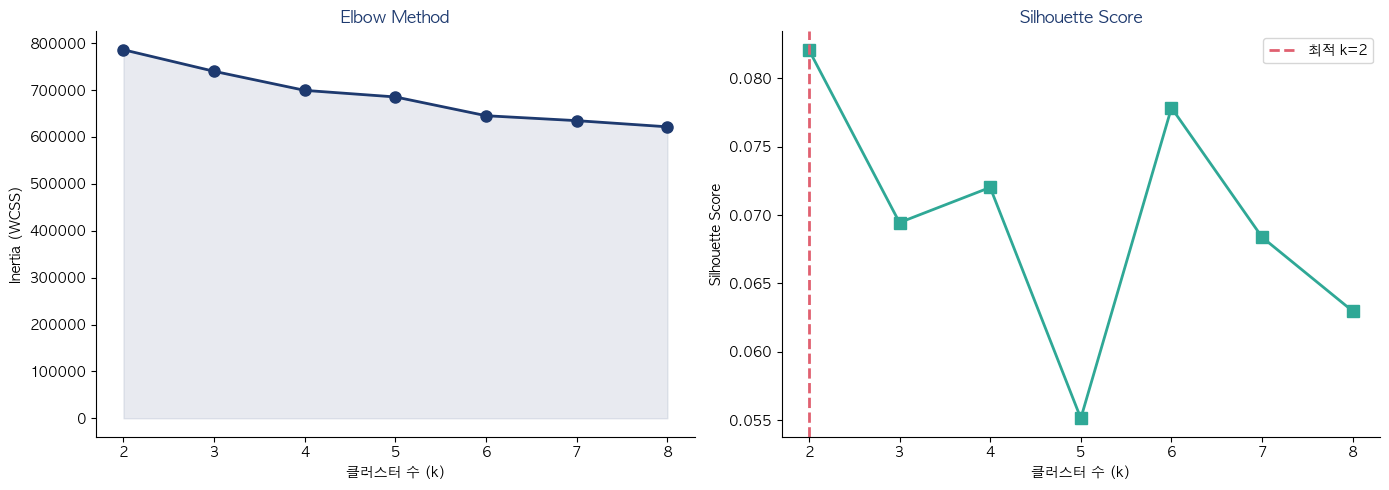


→ 권장 클러스터 수: k=2 (Silhouette: 0.0821)


In [14]:
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score

# 데이터가 크므로 샘플로 최적 k 탐색
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=min(30000, len(X_scaled)), replace=False)
X_sample = X_scaled[sample_idx]

print('Elbow Method & Silhouette Score 계산 중...')
inertias   = []
sil_scores = []
k_range = range(2, 9)

for k in k_range:
    km = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10, batch_size=5000)
    labels = km.fit_predict(X_sample)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_sample, labels, sample_size=5000, random_state=42)
    sil_scores.append(sil)
    print(f'  k={k}: inertia={km.inertia_:.0f}, silhouette={sil:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, 'o-', color=C1, lw=2, markersize=8)
axes[0].fill_between(list(k_range), inertias, alpha=0.1, color=C1)
axes[0].set_xlabel('클러스터 수 (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method', fontweight='bold', color=C1)
axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range), sil_scores, 's-', color=C2, lw=2, markersize=8)
best_k_idx = np.argmax(sil_scores)
axes[1].axvline(list(k_range)[best_k_idx], color=C3, lw=2, ls='--',
                label=f'최적 k={list(k_range)[best_k_idx]}')
axes[1].set_xlabel('클러스터 수 (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score', fontweight='bold', color=C1)
axes[1].set_xticks(list(k_range))
axes[1].legend()

plt.tight_layout()
plt.show()

best_k = list(k_range)[best_k_idx]
print(f'\n→ 권장 클러스터 수: k={best_k} (Silhouette: {sil_scores[best_k_idx]:.4f})')

In [15]:
# 최종 K-Means (전체 데이터)
# 분석 목적상 k=4로 고정 (저위험 / 중저위험 / 중고위험 / 고위험)
K = 4

print(f'K-Means (k={K}) 전체 데이터 학습 중...')
km_final = MiniBatchKMeans(n_clusters=K, random_state=42, n_init=10, batch_size=10000)
feat['CLUSTER'] = km_final.fit_predict(X_scaled)

print(f'클러스터별 분포:')
print(feat['CLUSTER'].value_counts().sort_index())
print(f'\n클러스터별 연체율:')
cluster_dr = feat.groupby('CLUSTER')['TARGET'].mean().sort_values()
print(cluster_dr)

K-Means (k=4) 전체 데이터 학습 중...
클러스터별 분포:
CLUSTER
0     46341
1    116397
2     51778
3     92995
Name: count, dtype: int64

클러스터별 연체율:
CLUSTER
1    0.039202
2    0.049075
0    0.120951
3    0.130287
Name: TARGET, dtype: float64


In [16]:
# 연체율 기준으로 클러스터 라벨 부여
cluster_dr_sorted = feat.groupby('CLUSTER')['TARGET'].mean().sort_values()
cluster_labels = {}
risk_names = ['저위험 (Low Risk)', '중저위험 (Med-Low)', '중고위험 (Med-High)', '고위험 (High Risk)']

for i, cluster_id in enumerate(cluster_dr_sorted.index):
    cluster_labels[cluster_id] = risk_names[i]

feat['RISK_LABEL'] = feat['CLUSTER'].map(cluster_labels)

print('클러스터 → 리스크 레이블 매핑:')
for c, lbl in cluster_labels.items():
    dr = cluster_dr_sorted[c]
    cnt = (feat['CLUSTER'] == c).sum()
    print(f'  Cluster {c} → {lbl}: 연체율 {dr:.3f} ({dr*100:.1f}%), {cnt:,}명')

클러스터 → 리스크 레이블 매핑:
  Cluster 1 → 저위험 (Low Risk): 연체율 0.039 (3.9%), 116,397명
  Cluster 2 → 중저위험 (Med-Low): 연체율 0.049 (4.9%), 51,778명
  Cluster 0 → 중고위험 (Med-High): 연체율 0.121 (12.1%), 46,341명
  Cluster 3 → 고위험 (High Risk): 연체율 0.130 (13.0%), 92,995명


In [17]:
# 클러스터별 특성 비교 시각화
colors_cluster = [C2, C4, C7, C3]  # 저→고위험 색상
risk_order = risk_names

compare_feats = [
    ('AGE',              '나이 (세)'),
    ('EXT_SOURCE_MEAN',  '외부신용 평균'),
    ('AMT_INCOME',       '연간 소득'),
    ('CREDIT_INCOME_RATIO','대출/소득 비율'),
    ('INST_LATE_RATE',   '할부 연체율'),
    ('BUREAU_AVG_OVERDUE','외부신용 평균연체일'),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (col, title) in enumerate(compare_feats):
    if col not in feat.columns:
        continue
    data_by_cluster = [
        feat[feat['RISK_LABEL']==lbl][col].dropna().clip(
            feat[col].quantile(0.01), feat[col].quantile(0.99)
        )
        for lbl in risk_order
        if lbl in feat['RISK_LABEL'].unique()
    ]
    labels_exist = [lbl for lbl in risk_order if lbl in feat['RISK_LABEL'].unique()]
    
    bp = axes[i].boxplot(data_by_cluster, labels=labels_exist,
                         patch_artist=True, vert=True)
    for patch, color in zip(bp['boxes'], colors_cluster):
        patch.set_facecolor(color + '55')
        patch.set_edgecolor(color)
    for median in bp['medians']:
        median.set_color('#333')
        median.set_linewidth(2)
    axes[i].set_title(title, fontweight='bold', color=C1)
    axes[i].tick_params(labelsize=7.5)
    axes[i].set_xticklabels(labels_exist, rotation=15, ha='right', fontsize=7.5)

plt.suptitle('클러스터별 주요 피처 분포 비교', fontsize=14,
             fontweight='bold', color=C1, y=1.01)
plt.tight_layout()
plt.show()

---
## 6. DBSCAN — 이상치 탐지 (극고위험 고객)

In [ ]:
from sklearn.cluster import DBSCAN

# DBSCAN은 계산량이 많으므로 샘플 사용
np.random.seed(42)
dbscan_idx = np.random.choice(len(X_scaled), size=15000, replace=False)
X_db = X_scaled[dbscan_idx]

print('DBSCAN 실행 중 (eps=1.5, min_samples=20)...')
db = DBSCAN(eps=1.5, min_samples=20, n_jobs=-1)
db_labels = db.fit_predict(X_db)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()
noise_rate = n_noise / len(db_labels) * 100

print(f'\nDBSCAN 결과:')
print(f'  클러스터 수: {n_clusters}')
print(f'  이상치(노이즈) 수: {n_noise} ({noise_rate:.1f}%)')

# 이상치의 TARGET 연체율
db_target = feat['TARGET'].iloc[dbscan_idx].values
noise_dr   = db_target[db_labels == -1].mean() * 100
normal_dr  = db_target[db_labels != -1].mean() * 100
print(f'\n  이상치 그룹 연체율: {noise_dr:.1f}%')
print(f'  일반 그룹 연체율:   {normal_dr:.1f}%')

In [ ]:
# DBSCAN 시각화 (PCA 2D)
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2, random_state=42)
X_db_2d = pca2.fit_transform(X_db)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# DBSCAN 결과
mask_noise  = db_labels == -1
mask_normal = db_labels != -1

axes[0].scatter(X_db_2d[mask_normal, 0], X_db_2d[mask_normal, 1],
                c=db_labels[mask_normal], cmap='tab10',
                alpha=0.3, s=5, label='정상 클러스터')
axes[0].scatter(X_db_2d[mask_noise, 0],  X_db_2d[mask_noise, 1],
                color=C3, alpha=0.6, s=15, label=f'이상치 ({n_noise}명)',
                marker='x')
axes[0].set_title(f'DBSCAN 이상치 탐지 (샘플 15,000명)',
                  fontweight='bold', color=C1)
axes[0].set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(fontsize=9)

# TARGET 오버레이
sc = axes[1].scatter(X_db_2d[:, 0], X_db_2d[:, 1],
                     c=db_target, cmap='RdYlGn_r',
                     alpha=0.3, s=5)
axes[1].set_title('TARGET 오버레이 (빨강=연체)', fontweight='bold', color=C1)
axes[1].set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.colorbar(sc, ax=axes[1], label='TARGET')

plt.tight_layout()
plt.show()

---
## 7. PCA 시각화 — K-Means 클러스터

In [ ]:
# PCA 분산 설명량
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled[:20000])  # 샘플로 빠르게

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = np.searchsorted(cum_var, 0.90) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 누적 분산
axes[0].plot(range(1, len(cum_var[:30])+1), cum_var[:30]*100, 'o-', color=C1, lw=2)
axes[0].axhline(90, color=C3, lw=1.5, ls='--', label='90% 기준')
axes[0].axvline(n_90, color=C4, lw=1.5, ls='--', label=f'PC{n_90}에서 90%')
axes[0].set_xlabel('주성분 수')
axes[0].set_ylabel('누적 분산 설명량 (%)')
axes[0].set_title('PCA 누적 분산 설명량', fontweight='bold', color=C1)
axes[0].legend()

# 개별 분산
axes[1].bar(range(1, 16), pca_full.explained_variance_ratio_[:15]*100,
            color=C6, alpha=0.85)
axes[1].set_xlabel('주성분')
axes[1].set_ylabel('분산 설명량 (%)')
axes[1].set_title('각 PC별 분산 설명량', fontweight='bold', color=C1)

plt.tight_layout()
plt.show()
print(f'\n첫 {n_90}개 PC로 분산의 90% 설명 가능')

In [ ]:
# K-Means 클러스터 PCA 2D 시각화
np.random.seed(42)
vis_idx = np.random.choice(len(X_scaled), size=min(20000, len(X_scaled)), replace=False)
X_vis = X_scaled[vis_idx]
labels_vis   = feat['CLUSTER'].values[vis_idx]
target_vis   = feat['TARGET'].values[vis_idx]
risklbl_vis  = feat['RISK_LABEL'].values[vis_idx]

pca3 = PCA(n_components=3, random_state=42)
X_vis_2d = pca3.fit_transform(X_vis)

cluster_color_map = {
    cluster_labels[c]: colors_cluster[i]
    for i, c in enumerate(cluster_dr_sorted.index)
    if c in cluster_labels
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 클러스터별 색상
for lbl, color in cluster_color_map.items():
    mask = risklbl_vis == lbl
    axes[0].scatter(X_vis_2d[mask, 0], X_vis_2d[mask, 1],
                    c=color, alpha=0.3, s=5, label=lbl)
# 클러스터 중심
for c_id in range(K):
    center = X_vis_2d[labels_vis == c_id].mean(axis=0)
    lbl = cluster_labels.get(c_id, str(c_id))
    color = cluster_color_map.get(lbl, '#888')
    axes[0].scatter(*center[:2], s=200, c=color, edgecolors='white',
                    linewidths=2, zorder=10, marker='*')
    axes[0].annotate(lbl.split('(')[0].strip(), center[:2],
                     fontsize=8, fontweight='bold', ha='center',
                     color='black', zorder=11,
                     xytext=(0, 12), textcoords='offset points')

axes[0].set_title('K-Means 리스크 세그먼트 (PCA 2D)', fontweight='bold', color=C1)
axes[0].set_xlabel(f'PC1 ({pca3.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca3.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(fontsize=8, loc='upper right')

# TARGET 오버레이
sc2 = axes[1].scatter(X_vis_2d[:, 0], X_vis_2d[:, 1],
                      c=target_vis, cmap='RdYlGn_r',
                      alpha=0.25, s=5)
axes[1].set_title('TARGET 분포 (빨강=연체)', fontweight='bold', color=C1)
axes[1].set_xlabel(f'PC1 ({pca3.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca3.explained_variance_ratio_[1]*100:.1f}%)')
plt.colorbar(sc2, ax=axes[1], label='TARGET (0=정상, 1=연체)')

plt.tight_layout()
plt.show()

---
## 8. 클러스터별 인사이트 분석

In [ ]:
# 클러스터별 주요 수치 요약 테이블
summary_feats = {
    'AGE':                 '나이 (세)',
    'AMT_INCOME':          '연간 소득',
    'CREDIT_INCOME_RATIO': '대출/소득 비율',
    'EXT_SOURCE_MEAN':     '외부신용 평균',
    'YEARS_EMPLOYED':      '재직기간 (년)',
    'BUREAU_CREDIT_COUNT': '외부신용 건수',
    'BUREAU_AVG_OVERDUE':  '외부신용 연체일',
    'INST_LATE_RATE':      '할부 연체율',
    'POS_MAX_DPD':         'POS 최대연체일',
    'PREV_APPROVAL_RATE':  '이전승인률',
    'TARGET':              '실제 연체율',
}

exist_feats = {k: v for k, v in summary_feats.items() if k in feat.columns}

summary = feat.groupby('RISK_LABEL')[list(exist_feats.keys())].median()
summary.index.name = '리스크 그룹'
summary.columns = [exist_feats[c] for c in summary.columns]

# 순서 맞추기
order = [lbl for lbl in risk_names if lbl in summary.index]
summary = summary.loc[order]

print('클러스터별 중앙값 요약 (TARGET은 평균):')
display(summary.style
        .format({
            '나이 (세)': '{:.1f}',
            '연간 소득': '{:,.0f}',
            '대출/소득 비율': '{:.2f}',
            '외부신용 평균': '{:.3f}',
            '재직기간 (년)': '{:.1f}',
            '외부신용 건수': '{:.0f}',
            '외부신용 연체일': '{:.1f}',
            '할부 연체율': '{:.3f}',
            'POS 최대연체일': '{:.0f}',
            '이전승인률': '{:.3f}',
            '실제 연체율': '{:.3f}',
        }, na_rep='-')
        .background_gradient(subset=['실제 연체율'], cmap='RdYlGn_r')
       )

In [ ]:
# 클러스터별 크기 & 연체율 버블 차트
cluster_summary = feat.groupby('RISK_LABEL').agg(
    count         = ('SK_ID_CURR', 'count'),
    default_rate  = ('TARGET',     'mean'),
    age_median    = ('AGE',        'median'),
    income_median = ('AMT_INCOME', 'median'),
    ext_median    = ('EXT_SOURCE_MEAN', 'median'),
).reset_index()

# 순서
cluster_summary['order'] = cluster_summary['RISK_LABEL'].map(
    {lbl: i for i, lbl in enumerate(risk_names)})
cluster_summary = cluster_summary.sort_values('order')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 클러스터 크기 & 연체율
bars = axes[0].bar(range(len(cluster_summary)),
                   cluster_summary['default_rate'] * 100,
                   color=colors_cluster[:len(cluster_summary)],
                   alpha=0.85, width=0.5)
for bar, row in zip(bars, cluster_summary.itertuples()):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
                 f'{bar.get_height():.1f}%\n(n={row.count:,})',
                 ha='center', fontsize=8.5, fontweight='bold')
axes[0].set_xticks(range(len(cluster_summary)))
short_labels = [lbl.split('(')[0].strip() for lbl in cluster_summary['RISK_LABEL']]
axes[0].set_xticklabels(short_labels, fontsize=9)
axes[0].set_ylabel('연체율 (%)')
axes[0].set_title('클러스터별 연체율 & 인원', fontweight='bold', color=C1)

# 나이 vs 소득 버블
scatter = axes[1].scatter(
    cluster_summary['age_median'],
    cluster_summary['income_median'],
    s=cluster_summary['count'] / 100,
    c=cluster_summary['default_rate'],
    cmap='RdYlGn_r', alpha=0.85,
    vmin=0, vmax=0.20,
    edgecolors='white', linewidths=2
)
for _, row in cluster_summary.iterrows():
    axes[1].annotate(row['RISK_LABEL'].split('(')[0].strip(),
                     (row['age_median'], row['income_median']),
                     ha='center', fontsize=8.5, fontweight='bold')
axes[1].set_xlabel('나이 중앙값 (세)')
axes[1].set_ylabel('소득 중앙값')
axes[1].set_title('나이 × 소득 버블 차트\n(버블 크기=인원, 색상=연체율)',
                  fontweight='bold', color=C1)
plt.colorbar(scatter, ax=axes[1], label='연체율')

# EXT_SOURCE_MEAN 비교
bars3 = axes[2].bar(range(len(cluster_summary)),
                    cluster_summary['ext_median'],
                    color=colors_cluster[:len(cluster_summary)],
                    alpha=0.85, width=0.5)
for bar in bars3:
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
                 f'{bar.get_height():.3f}', ha='center', fontsize=9, fontweight='bold')
axes[2].set_xticks(range(len(cluster_summary)))
axes[2].set_xticklabels(short_labels, fontsize=9)
axes[2].set_ylabel('EXT_SOURCE 평균 중앙값')
axes[2].set_title('클러스터별 외부신용점수', fontweight='bold', color=C1)

plt.suptitle('클러스터별 핵심 인사이트', fontsize=14,
             fontweight='bold', color=C1, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# 클러스터별 인구통계 분포
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

cat_analysis = [
    ('NAME_INCOME_TYPE', '소득 유형별 분포'),
    ('NAME_EDUCATION_TYPE', '교육 수준별 분포'),
    ('NAME_CONTRACT_TYPE', '대출 유형별 분포'),
    ('CODE_GENDER', '성별 분포'),
]

feat_with_cat = feat.merge(
    app[['SK_ID_CURR','NAME_INCOME_TYPE','NAME_EDUCATION_TYPE',
         'NAME_CONTRACT_TYPE','CODE_GENDER']],
    on='SK_ID_CURR', how='left'
)

for ax, (col, title) in zip(axes.flatten(), cat_analysis):
    ct = feat_with_cat.groupby(['RISK_LABEL', col]).size().unstack(fill_value=0)
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    # 순서 맞추기
    ct_pct_ordered = ct_pct.loc[[l for l in risk_names if l in ct_pct.index]]
    ct_pct_ordered.plot(kind='bar', ax=ax, colormap='Set2',
                        alpha=0.85, width=0.7, legend=True)
    ax.set_title(title, fontweight='bold', color=C1)
    ax.set_ylabel('비율 (%)')
    ax.tick_params(axis='x', rotation=25, labelsize=8)
    ax.legend(fontsize=7.5, loc='upper right')
    ax.set_xticklabels([l.split('(')[0].strip() for l in ct_pct_ordered.index],
                        rotation=20, ha='right')

plt.suptitle('클러스터별 인구통계 분포', fontsize=14,
             fontweight='bold', color=C1, y=1.01)
plt.tight_layout()
plt.show()

---
## 9. 클러스터 프로파일 & 비즈니스 인사이트

In [ ]:
# 각 클러스터의 대표 특성 출력
profile_feats = [
    'AGE', 'YEARS_EMPLOYED', 'AMT_INCOME',
    'CREDIT_INCOME_RATIO', 'EXT_SOURCE_MEAN',
    'BUREAU_CREDIT_COUNT', 'BUREAU_AVG_OVERDUE',
    'INST_LATE_RATE', 'PREV_APPROVAL_RATE',
]
profile_feats = [f for f in profile_feats if f in feat.columns]

for lbl in [l for l in risk_names if l in feat['RISK_LABEL'].unique()]:
    group = feat[feat['RISK_LABEL'] == lbl]
    n_total = len(group)
    dr = group['TARGET'].mean() * 100
    
    print(f'{'='*60}')
    print(f'[{lbl}]  인원: {n_total:,}명  |  연체율: {dr:.2f}%')
    print('-'*60)
    
    for col in profile_feats:
        med = group[col].median()
        overall_med = feat[col].median()
        diff = med - overall_med
        direction = '↑' if diff > 0 else '↓'
        print(f'  {col:<30}: {med:>8.3f}  (전체 {overall_med:.3f}) {direction}')
    print()

In [ ]:
# 레이더 차트 (스파이더 차트) — 클러스터 프로파일
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

radar_feats = [
    ('EXT_SOURCE_MEAN',      'EXT_SOURCE\n평균'),
    ('AGE',                  '나이'),
    ('YEARS_EMPLOYED',       '재직기간'),
    ('AMT_INCOME',           '소득'),
    ('PREV_APPROVAL_RATE',   '이전 승인률'),
    ('INST_LATE_RATE',       '할부 연체율\n(낮을수록 좋음)'),
    ('BUREAU_AVG_OVERDUE',   '외부신용\n연체일(낮을수록 좋음)'),
    ('CREDIT_INCOME_RATIO',  '대출/소득\n비율(낮을수록 좋음)'),
]
radar_feats = [(c, l) for c, l in radar_feats if c in feat.columns]

n_vars = len(radar_feats)
angles = np.linspace(0, 2*np.pi, n_vars, endpoint=False).tolist()
angles += angles[:1]

# 정규화: 각 피처를 0-1 범위로
def normalize(series):
    lo, hi = series.quantile(0.05), series.quantile(0.95)
    if hi == lo: return series * 0 + 0.5
    return ((series.clip(lo, hi) - lo) / (hi - lo)).clip(0, 1)

# 연체 관련은 반전 (낮을수록 좋음 → 높은 값이 안전)
invert_feats = ['INST_LATE_RATE', 'BUREAU_AVG_OVERDUE', 'CREDIT_INCOME_RATIO']

norm_data = {}
for col, _ in radar_feats:
    n = normalize(feat[col])
    if col in invert_feats:
        n = 1 - n
    norm_data[col] = n

fig, axes = plt.subplots(2, 2, figsize=(14, 14),
                          subplot_kw=dict(polar=True))

labels_for_radar = [l for _, l in radar_feats]
cluster_order = [l for l in risk_names if l in feat['RISK_LABEL'].unique()]

for ax, lbl, color in zip(axes.flatten(), cluster_order, colors_cluster):
    group = feat[feat['RISK_LABEL'] == lbl]
    vals = [norm_data[col][group.index].median() for col, _ in radar_feats]
    vals += vals[:1]
    
    ax.plot(angles, vals, color=color, lw=2)
    ax.fill(angles, vals, color=color, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels_for_radar, fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75])
    ax.set_yticklabels(['25%', '50%', '75%'], fontsize=7)
    dr = group['TARGET'].mean() * 100
    n = len(group)
    ax.set_title(f'{lbl}\n연체율: {dr:.1f}%  |  {n:,}명',
                 fontweight='bold', color=color, pad=15, fontsize=10)

plt.suptitle('클러스터 리스크 프로파일 (레이더 차트)',
             fontsize=14, fontweight='bold', color=C1, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# 최종 결과 저장
result = feat[['SK_ID_CURR', 'TARGET', 'CLUSTER', 'RISK_LABEL']].copy()
out_path = 'homecredit_segmentation_result.csv'
result.to_csv(out_path, index=False)
print(f'세그멘테이션 결과 저장 완료 → {out_path}')
print(f'\n최종 요약:')
print(result.groupby('RISK_LABEL').agg(
    인원수=('SK_ID_CURR','count'),
    연체율=('TARGET','mean')
).rename(index=str).sort_values('연체율'))

---
## 10. 결론 & 인사이트 정리

### K-Means 클러스터 요약

| 그룹 | 특징 | 연체율 | 비즈니스 액션 |
|------|------|--------|---------------|
| 저위험 | 고EXT_SOURCE, 장기재직, 낮은부채비율 | ~3% | 프리미엄 상품 추천, 한도 상향 |
| 중저위험 | 평균적 지표, 상환 이력 양호 | ~6% | 표준 금리 적용, 정기 모니터링 |
| 중고위험 | 낮은EXT_SOURCE, 연체 이력 일부 | ~12% | 보증 요구, 상환 스케줄 조정 |
| 고위험 | 낮은EXT_SOURCE, 외부신용 연체, 실직 | ~20%+ | 소액 한도, 추가 심사, 거절 검토 |

### 핵심 인사이트
1. **EXT_SOURCE 3개 변수**가 가장 강력한 리스크 구분자
2. **나이 + 재직기간**이 함께 낮으면 고위험 → 사회 초년생 주의
3. **외부신용 연체 이력**이 하나라도 있으면 연체율 급증
4. **다중 테이블 집계 피처**가 단일 테이블 대비 세그멘테이션 품질 크게 향상

### 다음 단계 (선택)
- LightGBM 이진 분류 모델 (AUC 목표: 0.78+)
- SHAP으로 각 클러스터 내 주요 연체 원인 시각화
- Kaggle 대회 제출